/tmp/ipykernel_1477400/2485120598.py:110: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(all_pathways, fontsize=FONT_SIZES['pathway_label'], fontweight="bold")


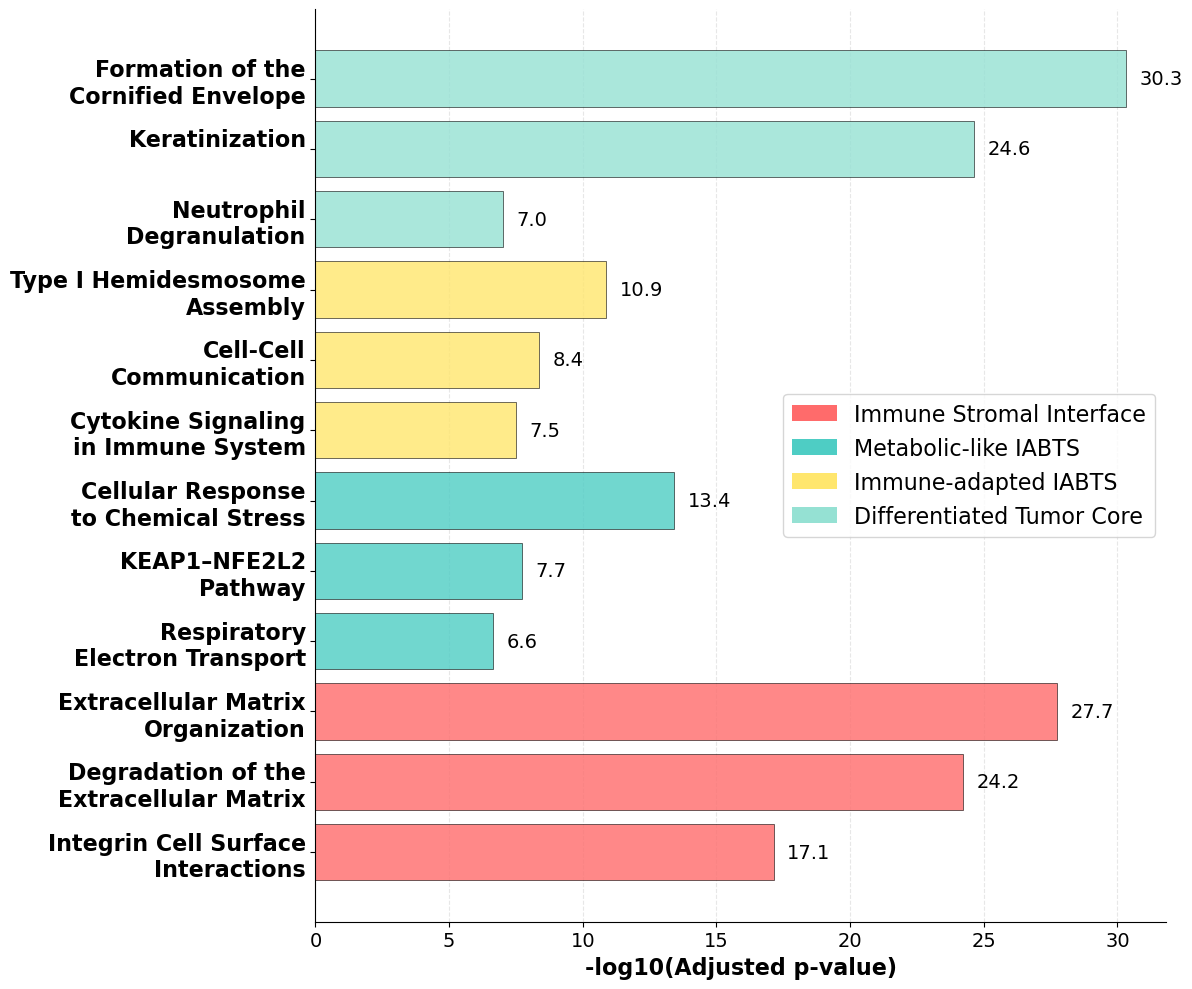

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ================= Font size settings =================
FONT_SIZES = {
    'pathway_label': 16,      # Pathway name font size
    'value_label': 14,        # Value label font size
    'axis_label': 16,         # Axis label font size
    'legend_label': 16        # Legend label font size
}

# Pathway results from Enrichr analysis at https://maayanlab.cloud/Enrichr/ (Reactome Pathways 2024 database) 
# using the top 100 marker genes per group from supplementary materials
pathways_data = {
    "Immune Stromal Interface": {
        "Extracellular Matrix Organization": 1.853e-28,
        "Degradation of the Extracellular Matrix": 5.931e-25,
        "Integrin Cell Surface Interactions": 7.177e-18
    },
    "Metabolic-like IABTS": {
        "Cellular Response to Chemical Stress": 0.00000000000003824,
        "KEAP1–NFE2L2 Pathway": 0.00000001858,
        "Respiratory Electron Transport": 0.0000002298
    },
    "Immune-adapted IABTS": {
        "Cytokine Signaling in Immune System": 0.00000003187,
        "Cell-Cell Communication": 0.000000004393,
        "Type I Hemidesmosome Assembly": 0.000000000013
    },
    "Differentiated Tumor Core": {
        "Formation of the Cornified Envelope": 4.873e-31,
        "Keratinization": 2.245e-25,
        "Neutrophil Degranulation": 0.00000009451
    }
}

# ================= Calculate communication strength =================
# Use -log10(adjusted p-value) as communication strength
for group in pathways_data:
    for pathway in pathways_data[group]:
        p_val = pathways_data[group][pathway]
        if p_val > 0:
            strength = -np.log10(p_val)
        else:
            strength = 50
        pathways_data[group][pathway] = strength

# ================= Define colors =================

group_colors = {
    "Immune Stromal Interface": "#FF6B6B",           # Red
    "Metabolic-like IABTS": "#4ECDC4",   # Cyan
    "Immune-adapted IABTS": "#FFE66D",   # Yellow
    "Differentiated Tumor Core": "#95E1D3"            # Light green
}

# ================= Plot horizontal bar chart =================

fig, ax = plt.subplots(figsize=(12, 10))

# Merge all pathways and sort by group
all_pathways = []
all_strengths = []
all_groups = []

for group in ['Immune Stromal Interface', 'Metabolic-like IABTS', 'Immune-adapted IABTS', 'Differentiated Tumor Core']:
    pathways = pathways_data[group]
    sorted_items = sorted(pathways.items(), key=lambda x: x[1])
    
    for pathway, strength in sorted_items:
        words = pathway.split()
        if len(words) > 1:
            # Calculate ending positions of each word (cumulative length + spaces)
            ends = []
            total = 0
            for w in words:
                total += len(w)
                ends.append(total)
                total += 1
        # Find the ending position closest to the center
        mid = len(pathway) / 2 + 0.1
        idx = min(range(len(ends)), key=lambda i: abs(ends[i] - mid))
        all_pathways.append(' '.join(words[:idx+1]) + '\n' + ' '.join(words[idx+1:]))
        all_strengths.append(strength)
        all_groups.append(group)

# Set color for each pathway
colors = [group_colors[g] for g in all_groups]

# Draw horizontal bar chart
bars = ax.barh(all_pathways, all_strengths, color=colors, alpha=0.8, 
               edgecolor='black', linewidth=0.5)

# Add value labels
for i, (strength, pathway) in enumerate(zip(all_strengths, all_pathways)):
    ax.text(strength + 0.5, i, f'{strength:.1f}', 
            va='center', ha='left', fontsize=FONT_SIZES['value_label'])

# Add legend
legend_elements = [Patch(facecolor=color, label=group) 
                   for group, color in group_colors.items()]
ax.legend(handles=legend_elements, loc='center right', fontsize=FONT_SIZES['legend_label'])

# Set axis labels and title
ax.set_xlabel('-log10(Adjusted p-value)', fontsize=FONT_SIZES['axis_label'], fontweight='bold')

# Set y-axis label (pathway name) font size
ax.set_yticklabels(all_pathways, fontsize=FONT_SIZES['pathway_label'], fontweight="bold")

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Keep left and bottom spines
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Add grid (only vertical grid lines)
ax.grid(axis='x', alpha=0.3, linestyle='--')
ax.set_axisbelow(True)
# Set x-axis tick label font size
ax.tick_params(axis='x', labelsize=FONT_SIZES['value_label'])

# Adjust layout
plt.tight_layout()
plt.show()